In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
units = pd.read_csv('units_L234.csv').copy()

In [ ]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

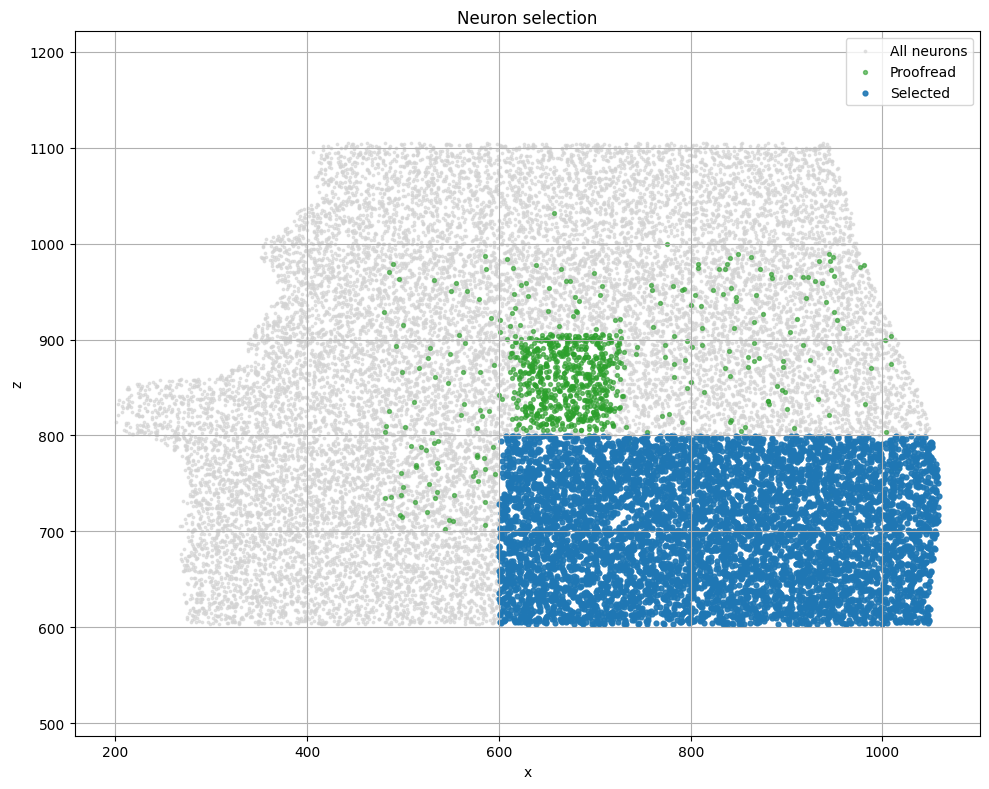

In [ ]:
units_cleaned = clean_dataset(units)

# Identification des neurones proofread
proofread_mask = (
    units_cleaned["strategy_axon"]
    .fillna("none")
    .ne("none")
)

non_proofread_mask = ~proofread_mask

# Sélection de la région étudiée
selected_mask = (
    (units_cleaned["pt_position_z"] < 800)
    & (units_cleaned["pt_position_x"] > 600)
)

# Effectifs globaux
n_total = len(units_cleaned)
n_proofread = int(proofread_mask.sum())
n_non_proofread = int(non_proofread_mask.sum())

# Effectifs dans la région sélectionnée
n_selected = int(selected_mask.sum())
n_selected_proofread = int((selected_mask & proofread_mask).sum())
n_selected_non_proofread = int(
    (selected_mask & non_proofread_mask).sum()
)

plt.figure(figsize=(10, 8))

# Neurones non proofread
plt.scatter(
    units_cleaned.loc[non_proofread_mask, "pt_position_x"],
    units_cleaned.loc[non_proofread_mask, "pt_position_z"],
    s=3,
    alpha=0.6,
    color="lightgray",
    label=f"Non-proofread (n={n_non_proofread:,})",
)

# Neurones proofread
plt.scatter(
    units_cleaned.loc[proofread_mask, "pt_position_x"],
    units_cleaned.loc[proofread_mask, "pt_position_z"],
    s=8,
    alpha=0.6,
    color="tab:green",
    label=f"Proofread (n={n_proofread:,})",
)

# Neurones sélectionnés
plt.scatter(
    units_cleaned.loc[selected_mask, "pt_position_x"],
    units_cleaned.loc[selected_mask, "pt_position_z"],
    s=12,
    alpha=0.9,
    color="tab:blue",
    label=(
        f"Selected region (n={n_selected:,}; "
        f"proofread={n_selected_proofread:,}; "
        f"non-proofread={n_selected_non_proofread:,})"
    ),
)

plt.xlabel("x")
plt.ylabel("z")
plt.title("Neuron selection")

plt.axis("equal")
plt.grid(alpha=0.3)

plt.legend(
    title=f"Total neurons: {n_total:,}",
    markerscale=2,
)

plt.tight_layout()
plt.show()

In [5]:
mask_exc = (units_cleaned['classification_system'] == 'excitatory_neuron')
mask_inh = (units_cleaned['classification_system'] == 'inhibitory_neuron')

mask_l23 = (units_cleaned['layer'] == 'L2/3')
mask_l4 = (units_cleaned['layer'] == 'L4')

In [6]:
E_L23 = units_cleaned[mask_exc & mask_l23 & selected_mask].copy().reset_index(drop=True)
I_L23 = units_cleaned[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = units_cleaned[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = units_cleaned[mask_inh & mask_l4].copy().reset_index(drop=True)

In [7]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [8]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [9]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [10]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [11]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs = all_pairs.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [12]:


def build_dataset(pre_pop, post_pop, synapses, metric=['Euclidean']):
    """
    Builds a DataFrame with features and labels for a given pathway.
    """
    #Get the connections and the potential pairs.
    
    conn_dist = existing_connections_v1(pre_pop, post_pop, synapses, metric)
    print(len(conn_dist))
    
    pot_dist = potential_connections_v1(pre_pop, post_pop, metric)
    print(len(pot_dist))

    """conn_dist = conn_dist.copy()
    pot_dist = pot_dist.copy()"""

    conn_dist['label'] = 1
    pot_dist['label'] = 0

    df = pd.concat([conn_dist, pot_dist], ignore_index=True)

    df = df.drop_duplicates(
        subset=['pre_pt_root_id', 'post_pt_root_id'],
        keep='first'   # garde conn_dist car on l’a mis en premier
    )
    global id_map, all_ids
    all_ids = pd.Index(pd.concat([
    df['pre_pt_root_id'],
    df['post_pt_root_id']
    ]).unique())
    id_map = {id_: i for i, id_ in enumerate(all_ids)}

    # active_ids = pd.Index(pd.concat([
    #     conn_dist['pre_pt_root_id'],
    #     conn_dist['post_pt_root_id']
    # ]).unique())

    # active_ids_index = active_ids.map(id_map).values



    pre_idx = df['pre_pt_root_id'].map(id_map).values
    post_idx = df['post_pt_root_id'].map(id_map).values


    
    features = ['euclidean']
    print(f'metri vaut {metric}')
    if 'Ori_Diff' in metric:
        features.append('ori_diff_polar')

    X = df[features].values
    y = df['label'].values

    return X, y, features, pre_idx, post_idx

In [13]:
path, pre, post = pathways[0]
X, y, features, pre_idx, post_idx = build_dataset(pre, post, synapses, metric=['Euclidean'])

71408
11611056
metri vaut ['Euclidean']


In [14]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = "checkpoints_embedding_MLP_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 30
PATIENCE = 5
LR = 1e-2
DIMS = [9,10,11,12,13,14,15]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [15]:
# =========================
# Model
# =========================


class EmbeddingModel(nn.Module):
    def __init__(
        self,
        n_neurons,
        dim=2,
        hidden=64
    ):
        super().__init__()

        self.dim = dim

        self.Z = nn.Embedding(n_neurons, dim)
        nn.init.normal_(self.Z.weight, mean=0.0, std=0.1)

        input_dim = 2 * dim

        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward_logits(self, pre_idx, post_idx):
        z_pre = self.Z(pre_idx)
        z_post = self.Z(post_idx)

        x = torch.cat([z_pre, z_post], dim=1)

        logits = self.mlp(x).squeeze(1)

        return logits

    def forward(self, pre_idx, post_idx):
        return torch.sigmoid(
            self.forward_logits(pre_idx, post_idx)
        )

In [16]:
# =========================
# Data
# =========================

_, y, _, pre_idx, post_idx = build_dataset(
    pre, post, synapses,
    metric=["Euclidean"]
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)

n_neurons = int(max(pre_idx.max(), post_idx.max()).item()) + 1
print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())

pre_idx = pre_idx.to(DEVICE)
post_idx = post_idx.to(DEVICE)
y = y.to(DEVICE)

dataset = TensorDataset(pre_idx, post_idx, y)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

71408
11611056
metri vaut ['Euclidean']
n_neurons: 3408
n_pairs: 11611056
positive rate: 0.006150000263005495


In [17]:
# =========================
# Eval
# =========================

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_y = []
    all_preds = []

    with torch.no_grad():
        for pi, pj, yb in loader:

            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(yb)
            all_y.append(yb.cpu().numpy())
            all_preds.append(probs.cpu().numpy())

    all_y = np.concatenate(all_y)
    all_preds = np.concatenate(all_preds)

    auc = roc_auc_score(all_y, all_preds)

    return total_loss / len(loader.dataset), auc


In [18]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [19]:
import os

dim = 1  # change selon la dimension qui plante
"""bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

if os.path.exists(bad_path):
    os.remove(bad_path)
    print("Deleted:", bad_path)"""

'bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")\n\nif os.path.exists(bad_path):\n    os.remove(bad_path)\n    print("Deleted:", bad_path)'

In [20]:
import csv

log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

# Créer le fichier avec en-tête s'il n'existe pas
if not os.path.exists(log_csv_path):
    with open(log_csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

In [ ]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Créer le CSV s'il n'existe pas
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = EmbeddingModel(n_neurons=n_neurons, dim=dim).to(DEVICE)

    # Loss pondérée pour gérer le fort déséquilibre
    pos_weight = (y == 0).sum() / (y == 1).sum()
    #criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for pi, pj, yb in train_loader:
            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)

In [ ]:
import pickle
import h5py
import numpy as np
import pandas as pd

# ============================================================
# Paths
# ============================================================

FOUNDATION_PATH = "MICrONS\\readout_info\\foundation_model.pkl"
MICRONS_H5_PATH = "MICrONS\\microns.h5"
COREG_PATH = "coreg_v1300.csv"


# ============================================================
# Load files
# ============================================================

with open(FOUNDATION_PATH, "rb") as f:
    foundation = pickle.load(f)
    """{"session_scan": {
            mu: [mu_x, mu_x] #area of the vision field where focus on the neuron
            feature_weigth: [[128 features] * 4] visual caracteristic of this area learnt by a the model
        }
    }"""

h5 = h5py.File(MICRONS_H5_PATH, "r") #for more information see the folder on hugging face https://huggingface.co/datasets/NeuroBLab/MICrONS

coreg = pd.read_csv(COREG_PATH) #merging table with coreg["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]

print(coreg)


# ============================================================
# Build readout table
# ============================================================

def build_readout_df(model_dict, h5, model_name="model"):
    rows = []
    for session_scan, data in model_dict.items():
        if session_scan not in h5["sessions"]:
            print("Missing in h5:", session_scan)
            continue

        session, scan_idx = map(int, session_scan.split("_"))
        meta = h5["sessions"][session_scan]["meta"]
        print(meta.keys())
        unit_ids = meta["unit_ids"][:]
        weights = data["feature_weights"]
        mu = data["mu"]

        n = min(len(unit_ids), weights.shape[0], mu.shape[0])

        if len(unit_ids) != weights.shape[0]:
            print(
                f"WARNING {model_name} {session_scan}: "
                f"unit_ids={len(unit_ids)}, weights={weights.shape[0]}, using n={n}"
            )

        for i in range(n):
            rows.append({
                "model_name": model_name,
                "session": session,
                "scan_idx": scan_idx,
                "unit_id": int(unit_ids[i]),
                "readout_weight": weights[i].reshape(-1).astype(np.float32),
                "readout_mu_x": float(mu[i, 0]),
                "readout_mu_y": float(mu[i, 1]),
            })
    return pd.DataFrame(rows)


readout_df = build_readout_df(foundation, h5)


# ============================================================
# Clean coreg table
# ============================================================

coreg = coreg[
    ["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]
].copy()

coreg["session"] = coreg["session"].astype(int)
coreg["scan_idx"] = coreg["scan_idx"].astype(int)
coreg["unit_id"] = coreg["unit_id"].astype(int)
coreg["pt_root_id"] = coreg["pt_root_id"].astype(np.int64)
print(coreg["score"].describe())

print(coreg["residual"].describe())

# ============================================================
# Merge readouts with pt_root_id
# ============================================================

readout_with_root = readout_df.merge(
    coreg,
    on=["session", "scan_idx", "unit_id"],
    how="inner"
)

readout_with_root = readout_with_root[
    (readout_with_root["residual"] < 10)
    & (readout_with_root["score"] > 5)
].copy()

idx = (
    readout_with_root
    .groupby("pt_root_id")["score"]
    .idxmax()
)

readout_unique = (
    readout_with_root
    .loc[idx]
    .reset_index(drop=True)
)

print("readout_df:", readout_df.shape)
print("readout_with_root:", readout_with_root.shape)
print("readout_with_root:", readout_with_root.shape)
print("matched fraction:", len(readout_with_root) / len(readout_df))



       id_ref                       created_ref  valid_ref     volume  \
0      388868  2020-09-28 22:44:53.222573+00:00       True  292.63200   
1      357165  2020-09-28 22:44:28.479993+00:00       True  254.62144   
2      323782  2020-09-28 22:45:16.004514+00:00       True  354.07840   
3      452040  2020-09-28 22:45:19.539072+00:00       True  374.22530   
4      485026  2020-09-28 22:44:53.278972+00:00       True  292.83008   
...       ...                               ...        ...        ...   
83041  326990  2020-09-28 22:43:47.135816+00:00       True  317.94562   
83042  191219  2020-09-28 22:41:37.134630+00:00       True  347.67667   
83043  259262  2020-09-28 22:40:55.410396+00:00       True  334.41168   
83044  422837  2020-09-28 22:42:45.050377+00:00       True  304.70242   
83045  553999  2020-09-28 22:41:18.478532+00:00       True  368.10376   

         pt_supervoxel_id          pt_root_id     id  \
0       97536645708182218  864691135801936738      1   
1       947

In [23]:
# =========================
# Load best model for a given dimension
# =========================

import os
import torch
import numpy as np
import pandas as pd

DIM_TO_ANALYZE = 11

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# Recreate model
model = EmbeddingModel(
    n_neurons=n_neurons,
    dim=DIM_TO_ANALYZE
).to(DEVICE)

# Load checkpoint
ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Extract latent vectors Z
# =========================

with torch.no_grad():
    Z = model.Z.weight.detach().cpu().numpy()

print("Z shape:", Z.shape)   # (n_neurons, DIM_TO_ANALYZE)



# =========================
# Convert to DataFrame
# =========================

df_Z = pd.DataFrame(
    Z,
    columns=[f"z{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z["neuron_idx"] = np.arange(len(df_Z))

# Optional: map back to pt_root_id
# all_ids is the ordered list used when creating id_map
# all_ids[i] corresponds to row i in Z

df_Z["pt_root_id"] = np.array(all_ids)

df_Z_full = df_Z.merge(
    units_cleaned,
    on="pt_root_id",
    how="left"
)

print(df_Z_full.head())
print(df_Z_full.shape)

df_Z_full = df_Z_full.merge(readout_unique[ 
    [ "pt_root_id", 
     "readout_weight", 
     "readout_mu_x", 
     "readout_mu_y", 
     "session", 
     "scan_idx", 
     "unit_id", 
     "residual", 
     "score" ] ], 
     on="pt_root_id", how="left" )

df_Z_readout = df_Z_full[
    df_Z_full["readout_weight"].notna()
].copy().reset_index(drop=True)
latent_cols = [c for c in df_Z_readout.columns if c.startswith("z")]



Loaded model for dim=11
Best epoch: 10
Best val loss: 0.0284
Z shape: (3408, 11)
         z1        z2        z3        z4        z5        z6        z7  \
0  0.009547  0.093552 -0.244504 -0.682195  0.307843  0.066187  0.445565   
1  0.030678  0.674596  0.222179 -0.051013 -0.646226  0.879808  0.853432   
2 -0.941203 -0.153429 -0.061179  0.428708 -0.282421  0.463821  1.168435   
3 -0.047662  0.744530 -0.148553  0.583835 -0.259530  0.030468 -0.260166   
4 -0.247209  0.039560 -0.446875  0.010101  0.191525  0.132942 -0.483621   

         z8        z9       z10  ...          pt_root_id  pt_position_x  \
0 -0.559131 -0.598720 -0.139350  ...  864691134884804602     793.389404   
1 -0.597739 -0.250865  0.389364  ...  864691134885076730     890.064514   
2  0.002565 -1.365046 -0.505583  ...  864691134885518074     699.402466   
3  0.169788  0.477409 -0.979982  ...  864691134885576442     927.851685   
4  0.453792 -0.201949 -0.821133  ...  864691134885584634     754.282288   

   pt_position_y 

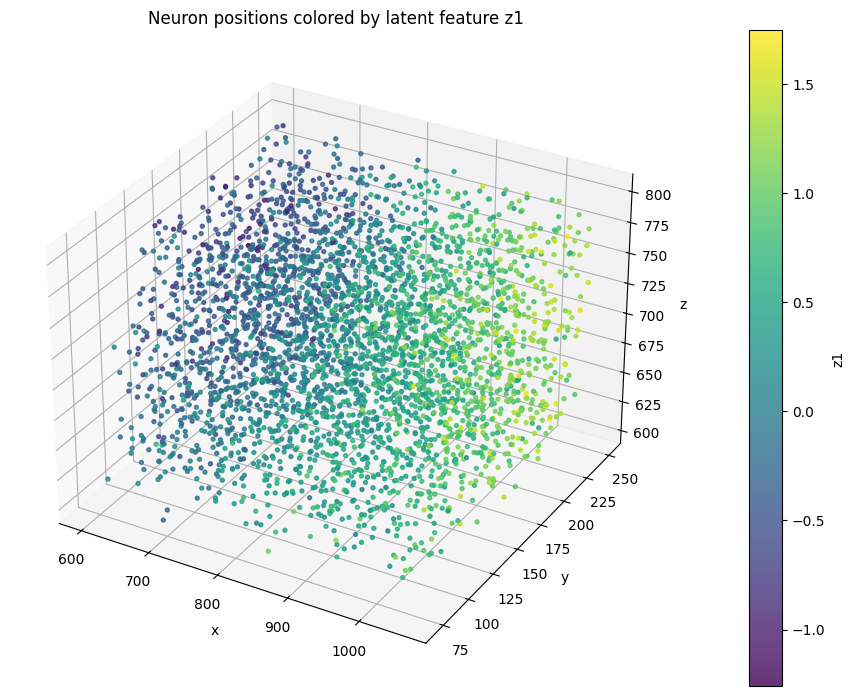

In [24]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df_plot = df_Z_full.dropna(
    subset=["pt_position_x", "pt_position_y", "pt_position_z", "z1"]
).copy()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df_plot["pt_position_x"],
    df_plot["pt_position_y"],
    df_plot["pt_position_z"],
    c=df_plot["z2"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Neuron positions colored by latent feature z1")

cbar = plt.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("z1")

plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_38668\4194641631.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


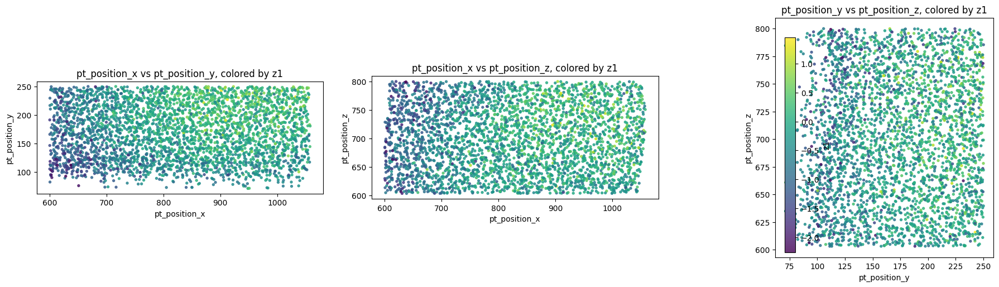

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [
    ("pt_position_x", "pt_position_y"),
    ("pt_position_x", "pt_position_z"),
    ("pt_position_y", "pt_position_z"),
]

for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(
        df_plot[a],
        df_plot[b],
        c=df_plot["z1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}, colored by z1")
    ax.set_aspect("equal", adjustable="box")

plt.colorbar(sc, ax=axes, label="z1")
plt.tight_layout()
plt.show()

In [26]:
for coord in ["pt_position_x", "pt_position_y", "pt_position_z"]:
    corr = df_plot["z1"].corr(df_plot[coord])
    print(f"corr(z1, {coord}) = {corr:.3f}")

corr(z1, pt_position_x) = 0.580
corr(z1, pt_position_y) = 0.363
corr(z1, pt_position_z) = 0.017


Original AUC: 0.9370668836547762
z1: AUC=0.8983 ± 0.0007 | drop=0.0388
z2: AUC=0.8836 ± 0.0007 | drop=0.0534
z3: AUC=0.9254 ± 0.0004 | drop=0.0117
z4: AUC=0.9114 ± 0.0005 | drop=0.0257
z5: AUC=0.9078 ± 0.0004 | drop=0.0292
z6: AUC=0.9150 ± 0.0003 | drop=0.0221
z7: AUC=0.8208 ± 0.0020 | drop=0.1163
z8: AUC=0.9145 ± 0.0003 | drop=0.0226
z9: AUC=0.9060 ± 0.0004 | drop=0.0311
z10: AUC=0.9248 ± 0.0001 | drop=0.0123
z11: AUC=0.9199 ± 0.0006 | drop=0.0172
   latent_dim  mean_auc   std_auc  auc_drop
0          z1  0.898258  0.000665  0.038809
1          z2  0.883623  0.000682  0.053443
2          z3  0.925403  0.000355  0.011664
3          z4  0.911416  0.000460  0.025651
4          z5  0.907842  0.000432  0.029224
5          z6  0.914972  0.000290  0.022094
6          z7  0.820776  0.002050  0.116291
7          z8  0.914452  0.000265  0.022615
8          z9  0.905953  0.000391  0.031114
9         z10  0.924772  0.000120  0.012295
10        z11  0.919902  0.000595  0.017165


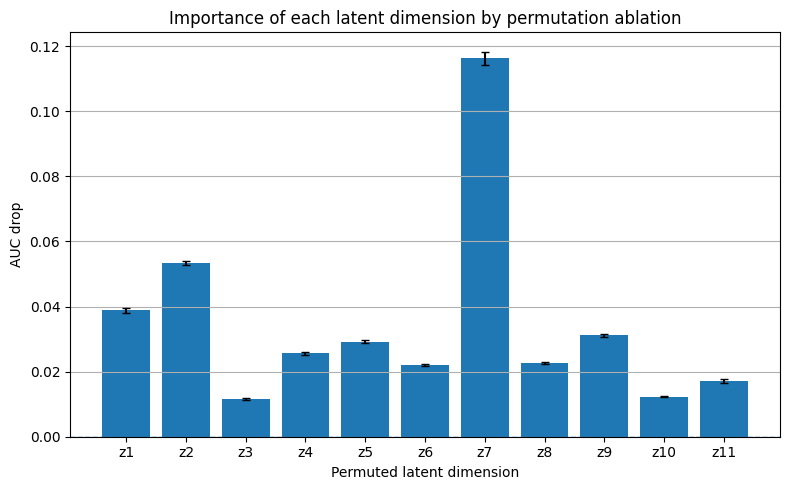

In [27]:
# ============================================================
# Ablation by permutation of each latent dimension
# ============================================================

from sklearn.metrics import roc_auc_score
import copy
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

BATCH_SIZE_PRED = 32768
N_PERMUTATIONS = 5
SEED = 42

# ------------------------------------------------------------
# Helper: predict probabilities by batch
# ------------------------------------------------------------

def predict_auc(model, pre_idx, post_idx, y, batch_size=32768):
    model.eval()

    probs = []

    with torch.no_grad():
        for start in range(0, len(y), batch_size):
            end = start + batch_size

            pre_b = pre_idx[start:end].to(DEVICE)
            post_b = post_idx[start:end].to(DEVICE)

            p_b = model(pre_b, post_b)

            probs.append(
                p_b.detach().cpu().numpy()
            )

    probs = np.concatenate(probs)

    y_np = (
        y.detach().cpu().numpy()
        if torch.is_tensor(y)
        else np.asarray(y)
    )

    auc = roc_auc_score(y_np, probs)

    return auc, probs


# ------------------------------------------------------------
# Make sure indices / labels are tensors
# ------------------------------------------------------------

if not torch.is_tensor(pre_idx):
    pre_idx_t = torch.tensor(pre_idx, dtype=torch.long)
else:
    pre_idx_t = pre_idx

if not torch.is_tensor(post_idx):
    post_idx_t = torch.tensor(post_idx, dtype=torch.long)
else:
    post_idx_t = post_idx

if not torch.is_tensor(y):
    y_t = torch.tensor(y, dtype=torch.float32)
else:
    y_t = y

# keep on CPU; batches are moved to GPU inside predict_auc
pre_idx_t = pre_idx_t.detach().cpu()
post_idx_t = post_idx_t.detach().cpu()
y_t = y_t.detach().cpu()


# ------------------------------------------------------------
# Baseline AUC
# ------------------------------------------------------------

baseline_auc, p_original = predict_auc(
    model,
    pre_idx_t,
    post_idx_t,
    y_t,
    batch_size=BATCH_SIZE_PRED
)

print("Original AUC:", baseline_auc)


# ------------------------------------------------------------
# Store original Z
# ------------------------------------------------------------

Z_original = model.Z.weight.detach().clone()

rng = np.random.default_rng(SEED)

results_ablation = []

# ------------------------------------------------------------
# Permute each latent dimension independently
# ------------------------------------------------------------

for k in range(DIM_TO_ANALYZE):

    aucs = []

    for rep in range(N_PERMUTATIONS):

        # restore original Z
        with torch.no_grad():
            model.Z.weight.copy_(Z_original)

        # create permutation of neuron indices
        perm = torch.tensor(
            rng.permutation(n_neurons),
            dtype=torch.long,
            device=DEVICE
        )

        # permute only dimension k
        with torch.no_grad():
            model.Z.weight[:, k] = model.Z.weight[perm, k]

        auc_k, _ = predict_auc(
            model,
            pre_idx_t,
            post_idx_t,
            y_t,
            batch_size=BATCH_SIZE_PRED
        )

        aucs.append(auc_k)

    results_ablation.append({
        "latent_dim": f"z{k+1}",
        "mean_auc": np.mean(aucs),
        "std_auc": np.std(aucs),
        "auc_drop": baseline_auc - np.mean(aucs),
    })

    print(
        f"z{k+1}: "
        f"AUC={np.mean(aucs):.4f} ± {np.std(aucs):.4f} | "
        f"drop={baseline_auc - np.mean(aucs):.4f}"
    )

# restore original model
with torch.no_grad():
    model.Z.weight.copy_(Z_original)

ablation_df = pd.DataFrame(results_ablation)

print(ablation_df)


# ============================================================
# Plot AUC drop by latent dimension
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    ablation_df["latent_dim"],
    ablation_df["auc_drop"],
    yerr=ablation_df["std_auc"],
    capsize=3
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Permuted latent dimension")
plt.ylabel("AUC drop")
plt.title("Importance of each latent dimension by permutation ablation")

plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_38668\776809946.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  curve = df.groupby("distance_bin").agg(


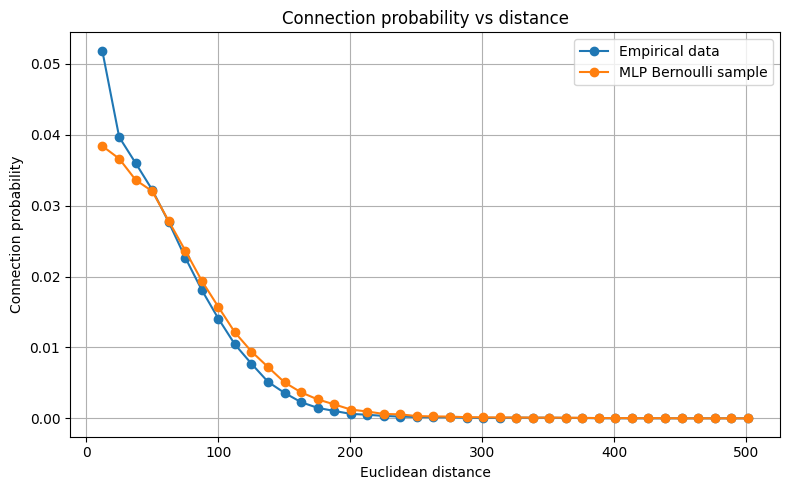

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# =========================
# 1. Pair ids
# =========================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

# =========================
# 2. Euclidean distances
# =========================

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(pre_pos - post_pos, axis=1)

# =========================
# 3. MLP probabilities
# =========================

model.eval()

with torch.no_grad():
    p_mlp = model(
        pre_idx.to(DEVICE),
        post_idx.to(DEVICE)
    ).cpu().numpy()

# =========================
# 4. Bernoulli realization
# =========================

rng = np.random.default_rng(42)

y_mlp = rng.binomial(
    n=1,
    p=p_mlp
)

y_emp = y.cpu().numpy()

# =========================
# 5. Build dataframe
# =========================

df = pd.DataFrame({
    "distance": distance,
    "empirical": y_emp,
    "mlp": y_mlp
})

df["distance_bin"] = pd.cut(
    df["distance"],
    bins=40
)

# =========================
# 6. Compute connection probability per bin
# =========================

curve = df.groupby("distance_bin").agg(
    empirical_prob=("empirical", "mean"),
    mlp_prob=("mlp", "mean"),
    n_pairs=("empirical", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# =========================
# 7. Plot
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    centers,
    curve["empirical_prob"],
    marker="o",
    label="Empirical data"
)

plt.plot(
    centers,
    curve["mlp_prob"],
    marker="o",
    label="MLP Bernoulli sample"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_38668\2810709212.py:73: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")



Analyzing dim = 1
Loaded best epoch: 27
Best val loss: 0.0343


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_38668\2810709212.py:181: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_38668\2810709212.py:210: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.058

Analyzing dim = 2
Loaded best epoch: 21
Best val loss: 0.0300


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_38668\2810709212.py:181: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_38668\2810709212.py:210: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


...

corr(geometrical distance, latent distance) = 0.669

Analyzing dim = 14
Loaded best epoch: 12
Best val loss: 0.0287


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_38668\2810709212.py:181: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_38668\2810709212.py:210: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.603

Analyzing dim = 15
Loaded best epoch: 12
Best val loss: 0.0286


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_38668\2810709212.py:181: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_38668\2810709212.py:210: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.629


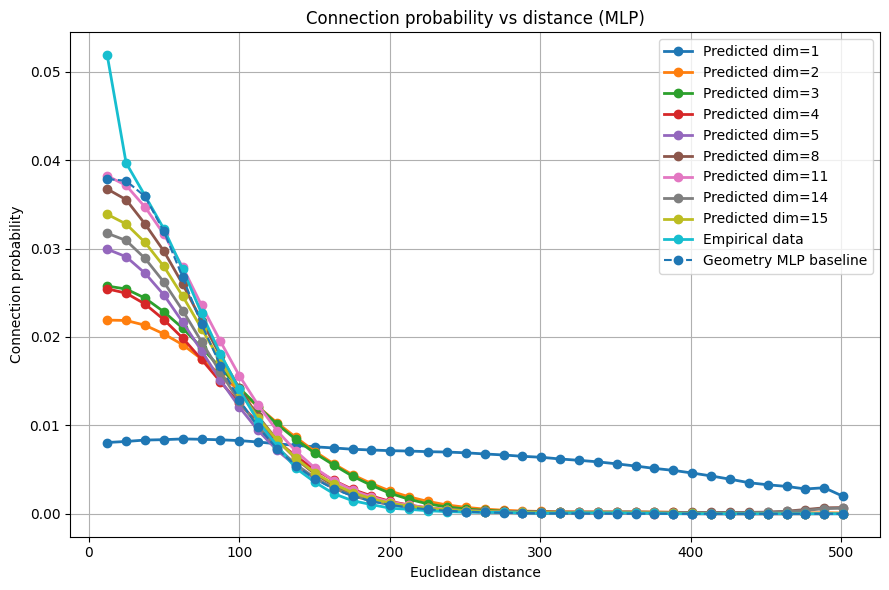

dim=15 corr=0.629


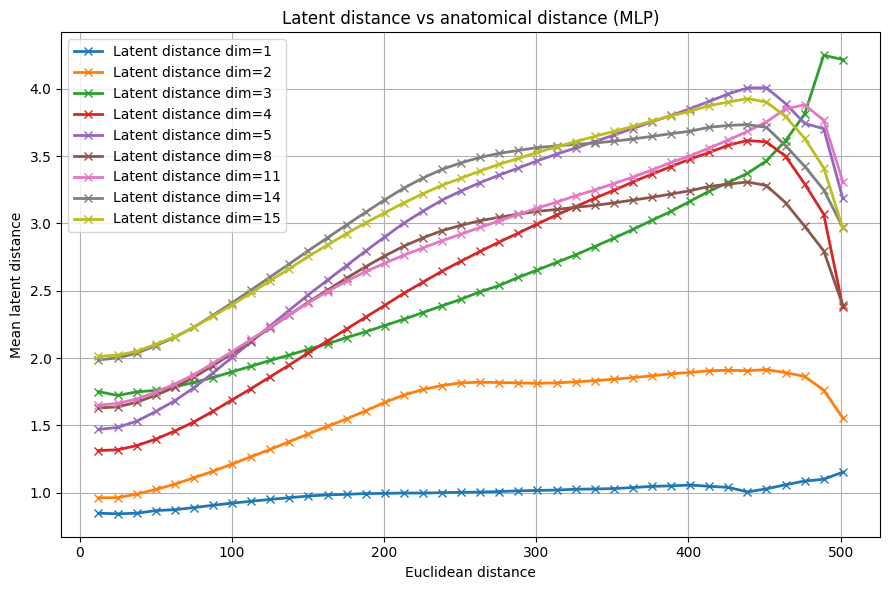

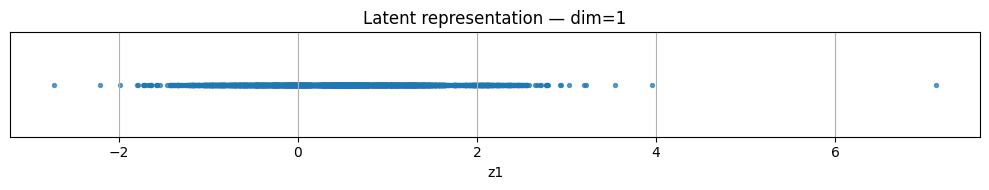

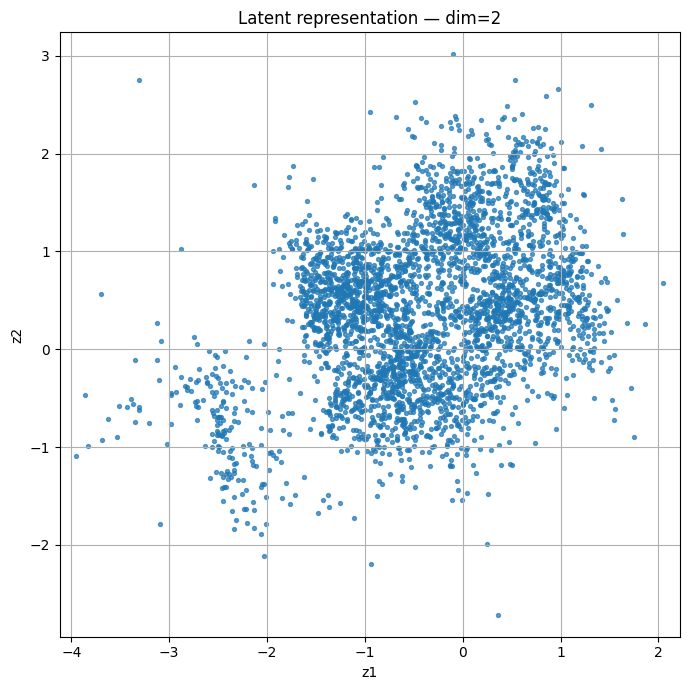

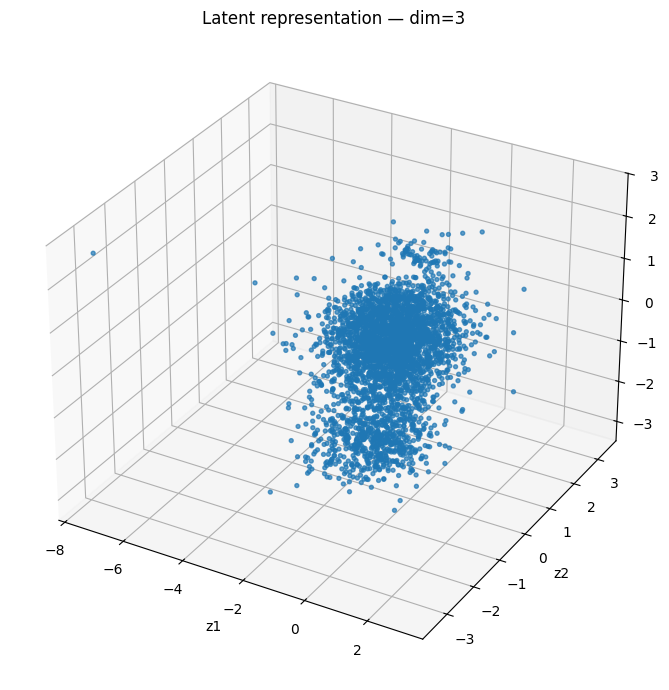

In [ ]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DIMS_TO_ANALYZE = [1, 2, 3]
N_BINS = 40
BATCH_SIZE = 32768


# ============================================================
# 1. Pair ids and Euclidean distances
# ============================================================

idx_to_id = np.array(all_ids)

pre_idx_np = pre_idx.cpu().numpy() if torch.is_tensor(pre_idx) else pre_idx
post_idx_np = post_idx.cpu().numpy() if torch.is_tensor(post_idx) else post_idx

pre_ids = idx_to_id[pre_idx_np]
post_ids = idx_to_id[post_idx_np]

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(
    pre_pos - post_pos,
    axis=1
)

y_emp = y.cpu().numpy() if torch.is_tensor(y) else y


# ============================================================
# 2. Common distance bins
# ============================================================

distance_bins = np.linspace(
    distance.min(),
    distance.max(),
    N_BINS + 1
)

distance_bin = pd.cut(
    distance,
    bins=distance_bins,
    include_lowest=True
)

bin_centers = np.array([
    b.mid for b in distance_bin.categories
])


# ============================================================
# 3. Empirical curve
# ============================================================

df_emp = pd.DataFrame({
    "distance": distance,
    "y": y_emp,
    "distance_bin": distance_bin,
})

emp_curve = (
    df_emp
    .groupby("distance_bin")
    .agg(
        empirical_prob=("y", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum"),
    )
)


# ============================================================
# 4. Containers for all dimensions
# ============================================================

predicted_curves = {}
latent_curves = {}
latent_spaces = {}


# ============================================================
# 5. Loop over dimensions
# ============================================================

for dim in DIMS_TO_ANALYZE:

    print("\n========================")
    print(f"Analyzing dim = {dim}")
    print("========================")

    ckpt_path = os.path.join(
        CHECKPOINT_DIR,
        f"best_dim_{dim}.pt"
    )

    model = EmbeddingModel(
        n_neurons=n_neurons,
        dim=dim
    ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    model.eval()

    print(f"Loaded best epoch: {ckpt['best_epoch']}")
    print(f"Best val loss: {ckpt['best_val_loss']:.4f}")

    # --------------------------------------------------------
    # Extract latent space
    # --------------------------------------------------------

    with torch.no_grad():
        Z = model.Z.weight.detach().cpu().numpy()

    latent_spaces[dim] = Z

    # --------------------------------------------------------
    # Predict probabilities in batches
    # --------------------------------------------------------

    all_probs = []

    with torch.no_grad():

        for start in range(0, len(y_emp), BATCH_SIZE):

            end = start + BATCH_SIZE

            pi = torch.as_tensor(
                pre_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            pj = torch.as_tensor(
                post_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            p_batch = model(
                pi,
                pj
            ).detach().cpu().numpy()

            all_probs.append(p_batch)

    p_pred = np.concatenate(all_probs)

    # --------------------------------------------------------
    # Predicted probability by anatomical distance
    # --------------------------------------------------------

    df_pred = pd.DataFrame({
        "distance": distance,
        "y": y_emp,
        "p_pred": p_pred,
        "distance_bin": distance_bin,
    })

    curve_pred = (
        df_pred
        .groupby("distance_bin")
        .agg(
            predicted_prob=("p_pred", "mean"),
            n_pairs=("p_pred", "size"),
        )
    )

    predicted_curves[dim] = curve_pred

    # --------------------------------------------------------
    # Latent distance by anatomical distance
    # --------------------------------------------------------

    z_pre = Z[pre_idx_np]
    z_post = Z[post_idx_np]

    latent_distance = np.linalg.norm(
        z_pre - z_post,
        axis=1
    )

    df_latent = pd.DataFrame({
        "geo_distance": distance,
        "latent_distance": latent_distance,
        "distance_bin": distance_bin,
    })

    curve_latent = (
        df_latent
        .groupby("distance_bin")
        .agg(
            mean_latent_distance=("latent_distance", "mean"),
            std_latent_distance=("latent_distance", "std"),
            n_pairs=("latent_distance", "size"),
        )
    )

    latent_curves[dim] = curve_latent

    corr = np.corrcoef(
        distance,
        latent_distance
    )[0, 1]

    print(
        f"corr(geometrical distance, latent distance) = {corr:.3f}"
    )


# ============================================================
# 6. Plot empirical + predicted probability for all dimensions
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        predicted_curves[dim]["predicted_prob"],
        marker="o",
        linewidth=2,
        label=f"Predicted dim={dim}"
    )

plt.plot(
    bin_centers,
    emp_curve["empirical_prob"],
    marker="o",
    linewidth=2,
    label="Empirical data"
)

baseline_curve = pd.read_csv(
        "baselines/geometry_mlp_probability_vs_distance.csv",
        index_col=0
    )

baseline_centers = np.array([
pd.Interval(left=float(s.split(",")[0][1:]),
            right=float(s.split(",")[1][:-1])).mid
for s in baseline_curve.index
])

plt.plot(
    baseline_curve["bin_center"],
    baseline_curve["predicted_prob"],
    marker="o",
    linestyle="--",
    label="Geometry MLP baseline"
)


plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance (MLP)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. Plot latent distance vs anatomical distance for all dims
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        latent_curves[dim]["mean_latent_distance"],
        marker="x",
        linewidth=2,
        label=f"Latent distance dim={dim}"
    )

    corr = np.corrcoef(
    distance,
    latent_distance
)[0,1]

print(
    f"dim={dim} "
    f"corr={corr:.3f}"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Mean latent distance")
plt.title("Latent distance vs anatomical distance (MLP)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. Latent representation dim = 1
# ============================================================

Z1 = latent_spaces[1]

plt.figure(figsize=(10, 2))

plt.scatter(
    Z1[:, 0],
    np.zeros(len(Z1)),
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.yticks([])
plt.title("Latent representation — dim=1")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. Latent representation dim = 2
# ============================================================

Z2 = latent_spaces[2]

plt.figure(figsize=(7, 7))

plt.scatter(
    Z2[:, 0],
    Z2[:, 1],
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Latent representation — dim=2")

plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. Latent representation dim = 3
# ============================================================

Z3 = latent_spaces[3]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    Z3[:, 0],
    Z3[:, 1],
    Z3[:, 2],
    s=8,
    alpha=0.7
)

ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_zlabel("z3")
ax.set_title("Latent representation — dim=3")

plt.tight_layout()
plt.show()

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr
from sklearn.decomposition import PCA


# ============================================================
# 1. Select latent and biological columns
# ============================================================

latent_cols = [
    c for c in df_Z_full.columns
    if c.startswith("z")
]

candidate_bio_cols = [
    "pt_position_x",
    "pt_position_y",
    "pt_position_z",
    "pref_ori_fit",
    "pref_dir_fit",
    "g_osi_dg",
    "g_dsi_dg",
    "firing_rate",
]

bio_cols = [
    c for c in candidate_bio_cols
    if c in df_Z_full.columns
]

print("Latent columns:", latent_cols)
print("Biological columns:", bio_cols)

Latent columns: ['z1', 'z2', 'z3', 'z4', 'z5', 'z6', 'z7', 'z8', 'z9', 'z10', 'z11']
Biological columns: ['pt_position_x', 'pt_position_y', 'pt_position_z', 'pref_ori_fit']


In [31]:
# ============================================================
# 2. Correlation matrix
# ============================================================

corr_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

corr_pearson = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

pval_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

for z in latent_cols:
    for b in bio_cols:

        tmp = df_Z_full[[z, b]].dropna()

        if len(tmp) < 5:
            corr_spearman.loc[z, b] = np.nan
            corr_pearson.loc[z, b] = np.nan
            pval_spearman.loc[z, b] = np.nan
            continue

        rho, pval = spearmanr(
            tmp[z],
            tmp[b]
        )

        r, _ = pearsonr(
            tmp[z],
            tmp[b]
        )

        corr_spearman.loc[z, b] = rho
        corr_pearson.loc[z, b] = r
        pval_spearman.loc[z, b] = pval

print("=== Spearman correlation ===")
print(corr_spearman)

print("\n=== Pearson correlation ===")
print(corr_pearson)

=== Spearman correlation ===
     pt_position_x  pt_position_y  pt_position_z  pref_ori_fit
z1        0.570268       0.363513       0.036574     -0.031703
z2        0.862586       0.054817      -0.090399     -0.044485
z3       -0.161496       0.443803       0.094739      0.004205
z4       -0.243314      -0.426978      -0.344217      0.051880
z5       -0.645024       0.094222       0.298883     -0.022264
z6        0.408383       0.095332      -0.496741      0.051038
z7       -0.703980       0.321848      -0.068426      0.109763
z8       -0.280075      -0.198375      -0.549669      0.079303
z9        0.088787      -0.429750       0.674525     -0.117277
z10       0.464160       0.060802       0.160257     -0.068334
z11       0.418629       0.017787       0.020473     -0.023390

=== Pearson correlation ===
     pt_position_x  pt_position_y  pt_position_z  pref_ori_fit
z1        0.580106       0.362512       0.016818     -0.035039
z2        0.852366       0.059664      -0.093909     -0.0407

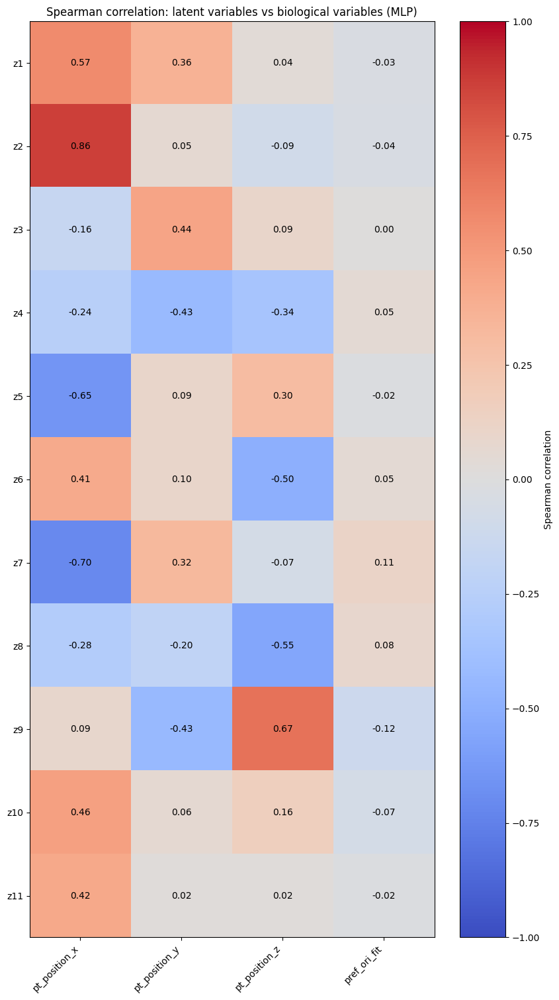

In [32]:
# ============================================================
# 3. Heatmap Spearman correlations
# ============================================================

plt.figure(figsize=(1.4 * len(bio_cols) + 3, 1.2 * len(latent_cols) + 2))

plt.imshow(
    corr_spearman.astype(float),
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.colorbar(
    label="Spearman correlation"
)

plt.xticks(
    ticks=np.arange(len(bio_cols)),
    labels=bio_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(latent_cols)),
    labels=latent_cols
)

for i, z in enumerate(latent_cols):
    for j, b in enumerate(bio_cols):
        val = corr_spearman.loc[z, b]

        if not np.isnan(val):
            plt.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                color="black"
            )

plt.title("Spearman correlation: latent variables vs biological variables (MLP)")
plt.tight_layout()
plt.show()

=== Strongest correlations ===
z2  pt_position_x    0.862586
z7  pt_position_x    0.703980
z9  pt_position_z    0.674525
z5  pt_position_x    0.645024
z1  pt_position_x    0.570268
z8  pt_position_z    0.549669
dtype: float64


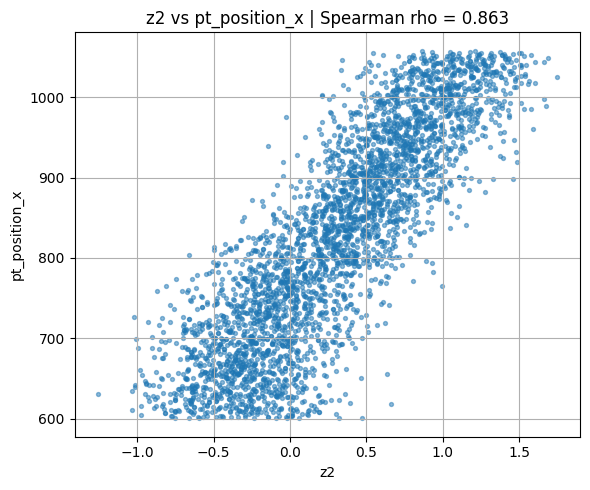

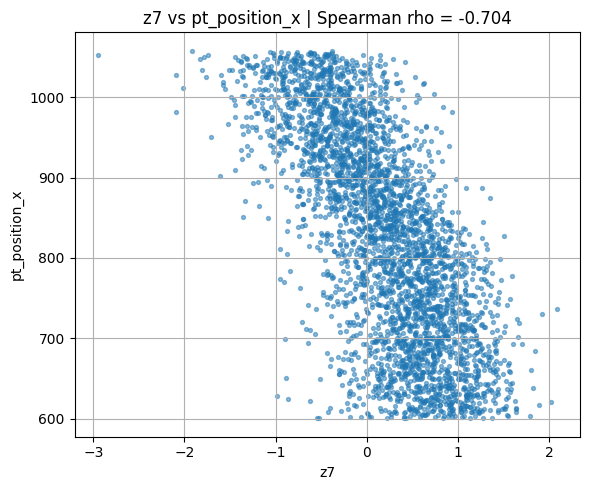

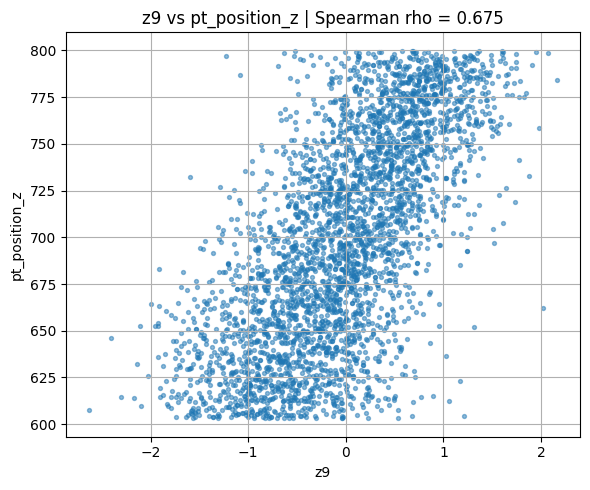

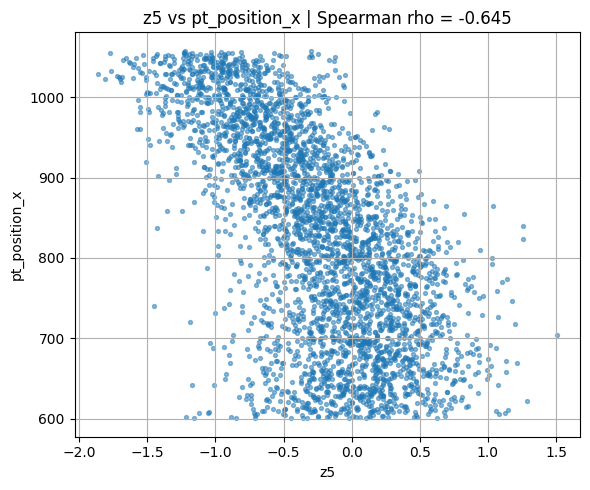

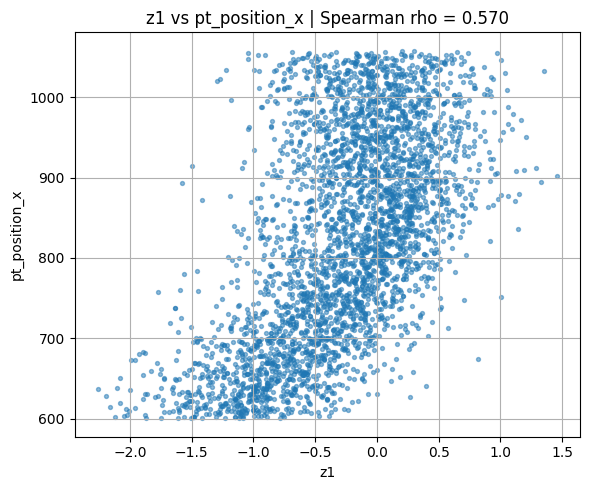

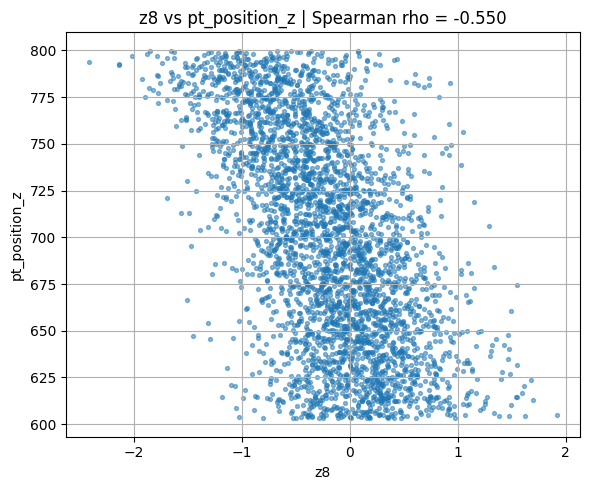

In [33]:
# ============================================================
# 4. Scatter plots for strongest correlations
# ============================================================

corr_abs = (
    corr_spearman
    .abs()
    .stack()
    .sort_values(ascending=False)
)

top_pairs = corr_abs.head(6)

print("=== Strongest correlations ===")
print(top_pairs)

for (z, b), _ in top_pairs.items():

    tmp = df_Z_full[[z, b]].dropna()

    plt.figure(figsize=(6, 5))

    plt.scatter(
        tmp[z],
        tmp[b],
        s=8,
        alpha=0.5
    )

    rho = corr_spearman.loc[z, b]

    plt.xlabel(z)
    plt.ylabel(b)
    plt.title(
        f"{z} vs {b} | Spearman rho = {rho:.3f}"
    )

    plt.grid(True)
    plt.tight_layout()
    plt.show()

PCA explained variance: [0.27471852 0.21435954]


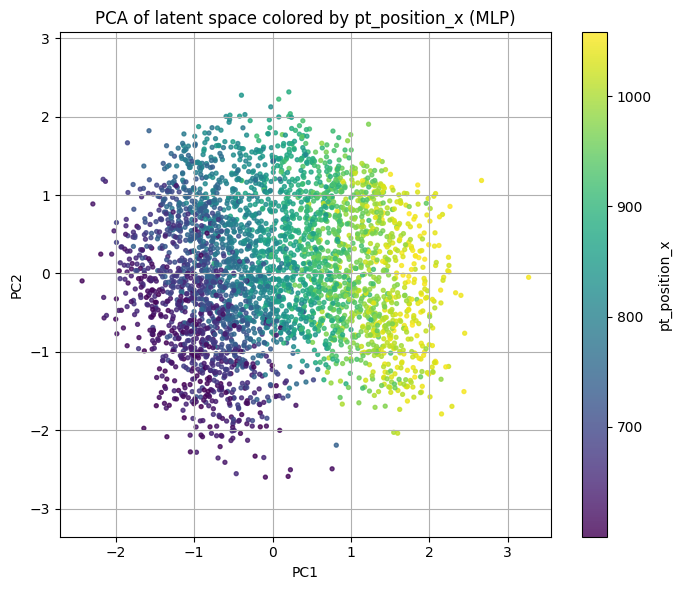

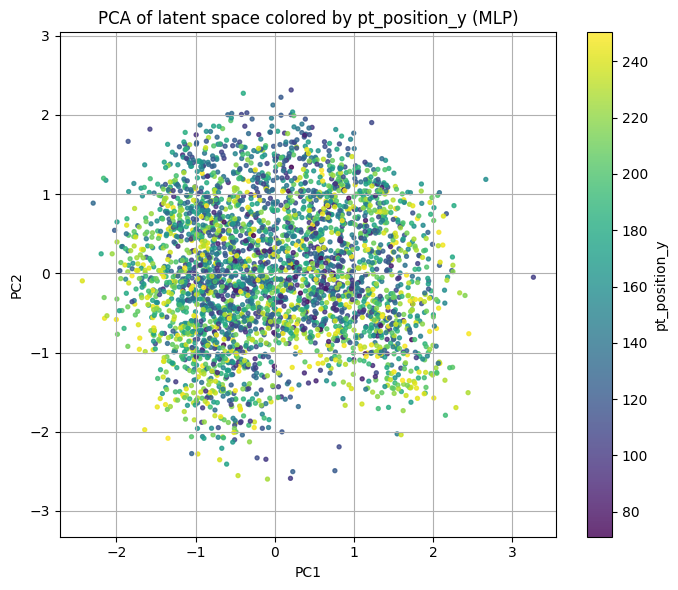

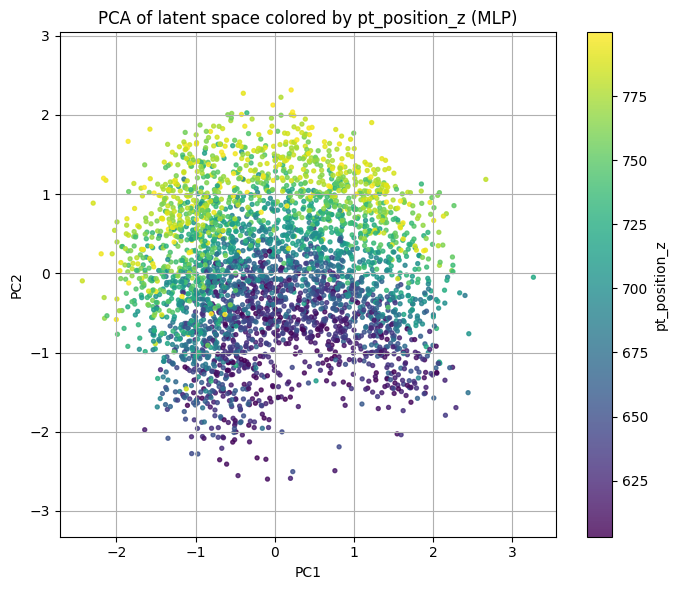

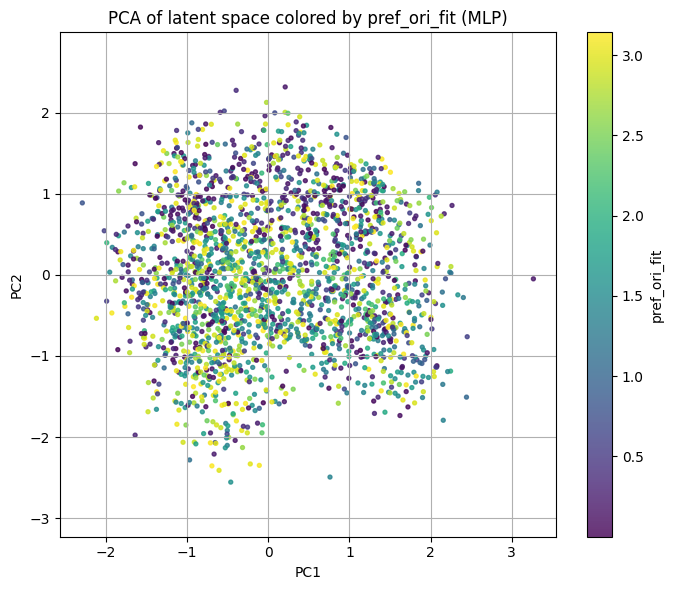

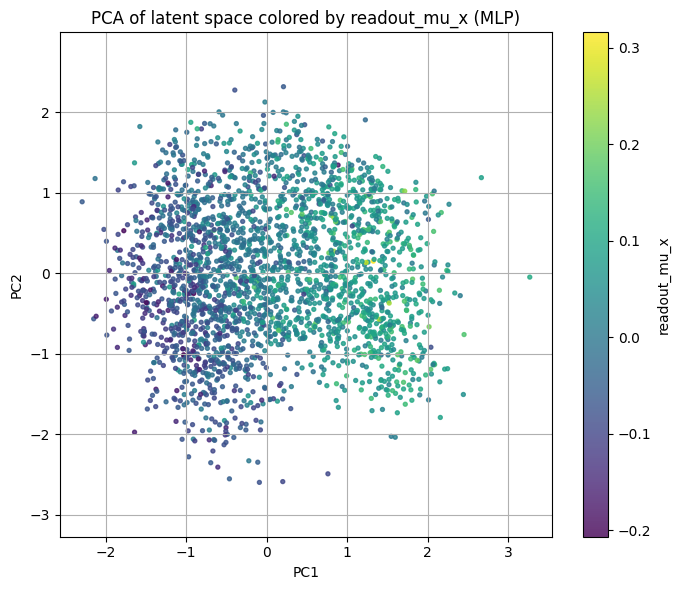

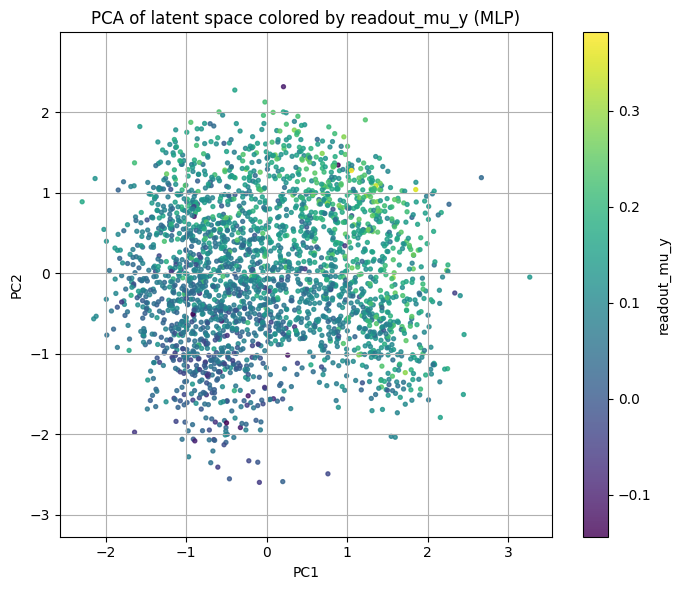

In [34]:
# ============================================================
# 5. PCA of latent embedding
# ============================================================

Z_cols = df_Z_full[latent_cols].dropna()

if len(latent_cols) >= 2:

    pca = PCA(n_components=2)

    Z_pca = pca.fit_transform(
        Z_cols.values
    )

    df_pca = df_Z_full.loc[
        Z_cols.index
    ].copy()

    df_pca["PC1"] = Z_pca[:, 0]
    df_pca["PC2"] = Z_pca[:, 1]

    print(
        "PCA explained variance:",
        pca.explained_variance_ratio_
    )

    color_cols = [
        c for c in [
            "pt_position_x",
            "pt_position_y",
            "pt_position_z",
            "pref_ori_fit",
            "g_osi_dg",
            "g_dsi_dg",
            "readout_mu_x",
            "readout_mu_y"
        ]
        if c in df_pca.columns
    ]

    for c in color_cols:

        tmp = df_pca[["PC1", "PC2", c]].dropna()

        plt.figure(figsize=(7, 6))

        sc = plt.scatter(
            tmp["PC1"],
            tmp["PC2"],
            c=tmp[c],
            s=8,
            alpha=0.8,
            cmap="viridis"
        )

        plt.xlabel("PC1")
        plt.ylabel("PC2")

        plt.title(
            f"PCA of latent space colored by {c} (MLP)"
        )

        plt.colorbar(sc, label=c)
        plt.axis("equal")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

else:
    print("PCA skipped: latent dimension < 2")

In [35]:
import pickle
import h5py
import pandas as pd

with open("MICrONS\\readout_info\\foundation_model.pkl", "rb") as f:
    foundation = pickle.load(f)

with open("MICrONS\\readout_info\\hierarchical_model.pkl", "rb") as f:
    hierarchical = pickle.load(f)

h5 = h5py.File("MICrONS\\microns.h5", "r")
print(h5.keys())

<KeysViewHDF5 ['brain_areas', 'sessions', 'types', 'videos']>


In [36]:
def explore_h5(g, prefix=""):
    for k in g.keys():
        item = g[k]
        path = f"{prefix}/{k}"
        print(path, type(item), getattr(item, "shape", ""))
        if isinstance(item, h5py.Group):
            explore_h5(item, path)

explore_h5(h5)

/brain_areas <class 'h5py._hl.group.Group'> 
/brain_areas/AL <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7 <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices/AL <class 'h5py._hl.dataset.Dataset'> (387,)
/brain_areas/AL/4_7/meta/area_indices/LM <class 'h5py._hl.dataset.Dataset'> (983,)
/brain_areas/AL/4_7/meta/area_indices/RL <class 'h5py._hl.dataset.Dataset'> (811,)
/brain_areas/AL/4_7/meta/area_indices/V1 <class 'h5py._hl.dataset.Dataset'> (5312,)
/brain_areas/AL/4_7/meta/brain_areas <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/meta/condition_hashes <class 'h5py._hl.dataset.Dataset'> (464,)
/brain_areas/AL/4_7/meta/coordinates <class 'h5py._hl.dataset.Dataset'> (7493, 3)
/brain_areas/AL/4_7/meta/unit_ids <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/trials <class 'h5py._hl.group.Group'> 
/brain_areas/

Z_latent: (2481, 11)
V_readout: (2481, 512)


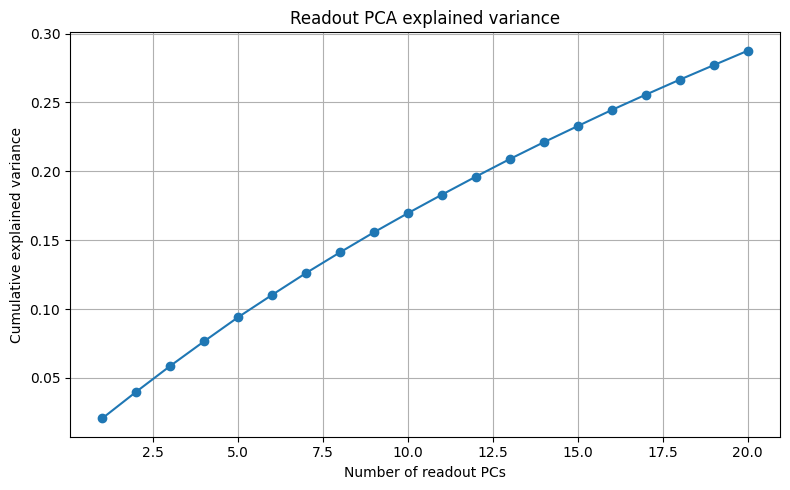


Readout PCs -> latent variables
   latent_dim  mean_cv_r2  std_cv_r2
0          z1    0.118698   0.023897
1          z2    0.287562   0.022711
2          z3    0.068985   0.022084
3          z4    0.047145   0.017840
4          z5    0.192643   0.038478
5          z6    0.083214   0.015109
6          z7    0.259320   0.026715
7          z8    0.061626   0.022608
8          z9    0.120852   0.029573
9         z10    0.090628   0.019697
10        z11    0.065689   0.020644


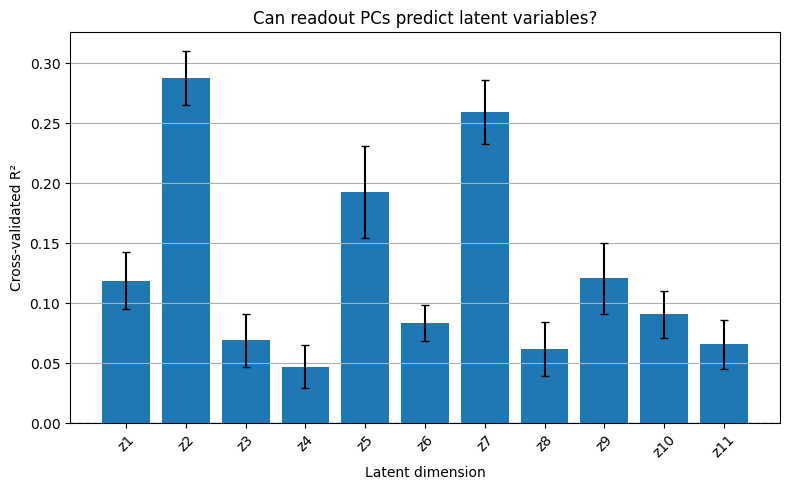


Latent variables -> readout PCs
   readout_pc  explained_variance  mean_cv_r2  std_cv_r2
0         PC1            0.020652    0.014207   0.003661
1         PC2            0.019315    0.031420   0.015768
2         PC3            0.018729    0.010787   0.022517
3         PC4            0.017908    0.024766   0.004379
4         PC5            0.017484    0.054942   0.021856
5         PC6            0.016197    0.116186   0.018162
6         PC7            0.015886    0.055409   0.016617
7         PC8            0.015007    0.042812   0.011781
8         PC9            0.014569    0.030801   0.009092
9        PC10            0.013885    0.014044   0.008148
10       PC11            0.013414    0.012284   0.005649
11       PC12            0.013107    0.035542   0.010030
12       PC13            0.012751    0.031279   0.013281
13       PC14            0.012214    0.027856   0.010533
14       PC15            0.011748    0.003541   0.002322
15       PC16            0.011638   -0.000270   0.00438

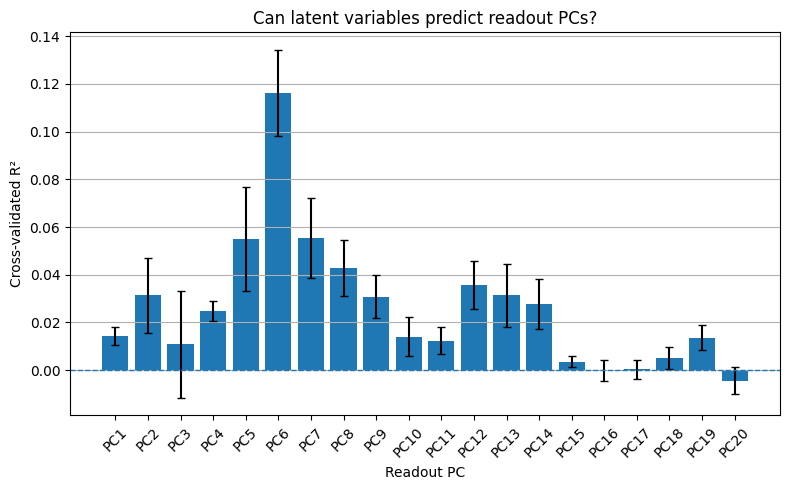

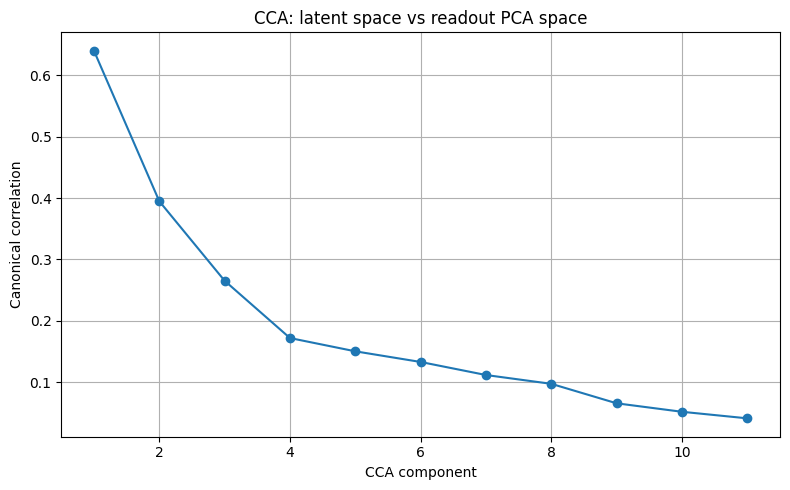


CCA correlations:
CCA 1: 0.6396
CCA 2: 0.3948
CCA 3: 0.2654
CCA 4: 0.1722
CCA 5: 0.1506
CCA 6: 0.1333
CCA 7: 0.1121
CCA 8: 0.0978
CCA 9: 0.0661
CCA 10: 0.0523
CCA 11: 0.0416

Best readout -> latent:
latent_dim          z2
mean_cv_r2    0.287562
std_cv_r2     0.022711
Name: 1, dtype: object

Best latent -> readout PC:
readout_pc                 PC6
explained_variance    0.016197
mean_cv_r2            0.116186
std_cv_r2             0.018162
Name: 5, dtype: object


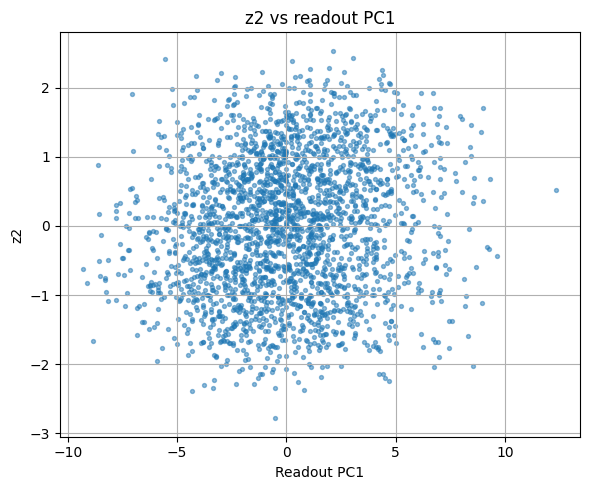

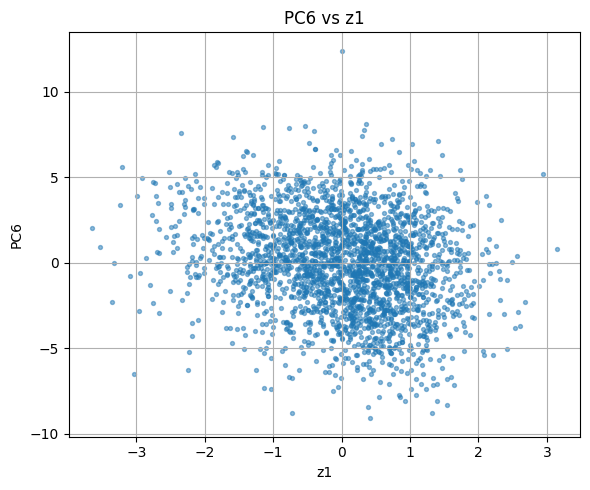

In [37]:
# ============================================================
# Relation between readout vectors and latent vectors
# 11D latent model
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.cross_decomposition import CCA
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import r2_score


# ============================================================
# 1. Build matrices
# ============================================================

latent_cols = [c for c in df_Z_readout.columns if c.startswith("z")]

Z_latent = df_Z_readout[latent_cols].to_numpy(dtype=np.float32)

V_readout = np.stack(
    df_Z_readout["readout_weight"].values
).astype(np.float32)

print("Z_latent:", Z_latent.shape)
print("V_readout:", V_readout.shape)


# ============================================================
# 2. Standardize
# ============================================================

Z_scaled = StandardScaler().fit_transform(Z_latent)
V_scaled = StandardScaler().fit_transform(V_readout)


# ============================================================
# 3. PCA of readout vectors
# ============================================================

N_READOUT_PCS = 20

pca_readout = PCA(
    n_components=N_READOUT_PCS,
    random_state=42
)

V_pca = pca_readout.fit_transform(V_scaled)

explained = pca_readout.explained_variance_ratio_

plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, N_READOUT_PCS + 1),
    np.cumsum(explained),
    marker="o"
)
plt.xlabel("Number of readout PCs")
plt.ylabel("Cumulative explained variance")
plt.title("Readout PCA explained variance")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 4. Regression: readout PCs -> latent variables
# ============================================================

alphas = np.logspace(-4, 4, 20)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

r2_readout_to_z = []

for z_col_idx, z_col in enumerate(latent_cols):

    y_target = Z_scaled[:, z_col_idx]

    model_reg = RidgeCV(
        alphas=alphas,
        cv=cv
    )

    scores = cross_val_score(
        model_reg,
        V_pca,
        y_target,
        cv=cv,
        scoring="r2"
    )

    r2_readout_to_z.append({
        "latent_dim": z_col,
        "mean_cv_r2": scores.mean(),
        "std_cv_r2": scores.std()
    })

r2_readout_to_z = pd.DataFrame(r2_readout_to_z)

print("\nReadout PCs -> latent variables")
print(r2_readout_to_z)

plt.figure(figsize=(8, 5))
plt.bar(
    r2_readout_to_z["latent_dim"],
    r2_readout_to_z["mean_cv_r2"],
    yerr=r2_readout_to_z["std_cv_r2"],
    capsize=3
)
plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Latent dimension")
plt.ylabel("Cross-validated R²")
plt.title("Can readout PCs predict latent variables?")
plt.xticks(rotation=45)
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()


# ============================================================
# 5. Regression: latent variables -> readout PCs
# ============================================================

r2_z_to_readout_pc = []

for pc_idx in range(N_READOUT_PCS):

    y_target = V_pca[:, pc_idx]

    model_reg = RidgeCV(
        alphas=alphas,
        cv=cv
    )

    scores = cross_val_score(
        model_reg,
        Z_scaled,
        y_target,
        cv=cv,
        scoring="r2"
    )

    r2_z_to_readout_pc.append({
        "readout_pc": f"PC{pc_idx+1}",
        "explained_variance": explained[pc_idx],
        "mean_cv_r2": scores.mean(),
        "std_cv_r2": scores.std()
    })

r2_z_to_readout_pc = pd.DataFrame(r2_z_to_readout_pc)

print("\nLatent variables -> readout PCs")
print(r2_z_to_readout_pc)

plt.figure(figsize=(8, 5))
plt.bar(
    r2_z_to_readout_pc["readout_pc"],
    r2_z_to_readout_pc["mean_cv_r2"],
    yerr=r2_z_to_readout_pc["std_cv_r2"],
    capsize=3
)
plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Readout PC")
plt.ylabel("Cross-validated R²")
plt.title("Can latent variables predict readout PCs?")
plt.xticks(rotation=45)
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()


# ============================================================
# 6. CCA between latent space and readout PCA space
# ============================================================

N_CCA = min(
    DIM_TO_ANALYZE,
    N_READOUT_PCS
)

cca = CCA(
    n_components=N_CCA,
    max_iter=1000
)

Z_cca, V_cca = cca.fit_transform(
    Z_scaled,
    V_pca
)

cca_corrs = []

for k in range(N_CCA):
    corr = np.corrcoef(
        Z_cca[:, k],
        V_cca[:, k]
    )[0, 1]

    cca_corrs.append(corr)

cca_corrs = np.array(cca_corrs)

plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, N_CCA + 1),
    cca_corrs,
    marker="o"
)
plt.xlabel("CCA component")
plt.ylabel("Canonical correlation")
plt.title("CCA: latent space vs readout PCA space")
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nCCA correlations:")
for i, c in enumerate(cca_corrs, start=1):
    print(f"CCA {i}: {c:.4f}")


# ============================================================
# 7. Scatter plots for strongest relations
# ============================================================

best_z = r2_readout_to_z.sort_values(
    "mean_cv_r2",
    ascending=False
).iloc[0]

best_pc = r2_z_to_readout_pc.sort_values(
    "mean_cv_r2",
    ascending=False
).iloc[0]

print("\nBest readout -> latent:")
print(best_z)

print("\nBest latent -> readout PC:")
print(best_pc)

best_z_name = best_z["latent_dim"]
best_z_idx = latent_cols.index(best_z_name)

best_pc_name = best_pc["readout_pc"]
best_pc_idx = int(best_pc_name.replace("PC", "")) - 1

plt.figure(figsize=(6, 5))
plt.scatter(
    V_pca[:, 0],
    Z_scaled[:, best_z_idx],
    s=8,
    alpha=0.5
)
plt.xlabel("Readout PC1")
plt.ylabel(best_z_name)
plt.title(f"{best_z_name} vs readout PC1")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(
    Z_scaled[:, 0],
    V_pca[:, best_pc_idx],
    s=8,
    alpha=0.5
)
plt.xlabel("z1")
plt.ylabel(best_pc_name)
plt.title(f"{best_pc_name} vs z1")
plt.grid(True)
plt.tight_layout()
plt.show()

Number of neurons: 2481
Readout shape: (2481, 512)
Latent shape: (2481, 11)

Best linear parameters:
{'regressor__ridge__alpha': np.float64(1000.0)}

Best MLP parameters:
{'regressor__mlp__alpha': 0.0001, 'regressor__mlp__hidden_layer_sizes': (32,)}

Whole-vector test metrics:


,test_R2,explained_variance,mean_euclidean,median_euclidean,mean_cosine,median_cosine
model,,,,,,
Linear,0.1576,0.1594,2.9814,2.8878,0.3672,0.4467
Linear shuffled,-0.0685,-0.0637,3.3741,3.3535,-0.0136,-0.0062
MLP,0.0295,0.0312,3.2094,3.1557,0.3177,0.3645
MLP shuffled,-0.1799,-0.1728,3.5509,3.5514,0.0247,0.0220



Test R2 for each latent dimension:


,latent_dimension,Linear,Linear shuffled,MLP,MLP shuffled
0,z1,0.1715,-0.1084,0.0800,-0.1700
1,z2,0.3428,-0.0678,0.2071,-0.2060
2,z3,0.1136,-0.0766,0.0517,-0.1726
3,z4,0.0709,-0.0635,-0.0783,-0.2426
4,z5,0.2486,-0.0426,0.0209,-0.1058
5,z6,0.1331,-0.1134,-0.0281,-0.2190
6,z7,0.3209,-0.0372,0.1247,-0.1925
7,z8,0.1087,-0.0507,0.0308,-0.1609
8,z9,0.1213,-0.0540,0.0116,-0.1371
9,z10,0.0956,-0.0828,-0.0348,-0.2480


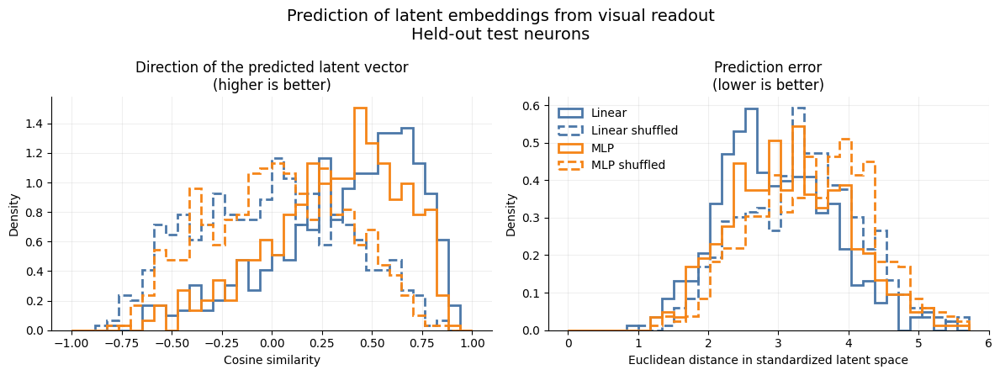

In [38]:
# ============================================================
# How much of the latent vector Z is explained by visual readout?
#
# Models:
#   1. Linear Ridge regression
#   2. Nonlinear MLP
#   3. Ridge trained with shuffled readout/Z pairing
#   4. MLP trained with shuffled readout/Z pairing
#
# Evaluation:
#   - Hyperparameters selected by cross-validation on training neurons
#   - Final metrics calculated only on held-out test neurons
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    r2_score,
    explained_variance_score,
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# Parameters
# ============================================================

SEED = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
N_JOBS = -1


# ============================================================
# Data
#
# R: visual readout vectors
# Z: complete latent embedding vectors
# ============================================================

latent_cols = sorted(
    [c for c in df_Z_readout.columns if c.startswith("z")],
    key=lambda c: int(c[1:]),
)

R = np.stack(
    df_Z_readout["readout_weight"].to_numpy()
).astype(np.float32)

Z_observed = df_Z_readout[
    latent_cols
].to_numpy(dtype=np.float32)


# Remove neurons containing invalid values
valid_rows = (
    np.isfinite(R).all(axis=1)
    & np.isfinite(Z_observed).all(axis=1)
)

R = R[valid_rows]
Z_observed = Z_observed[valid_rows]

n_neurons_analysis = len(R)
n_latent = Z_observed.shape[1]

print("Number of neurons:", n_neurons_analysis)
print("Readout shape:", R.shape)
print("Latent shape:", Z_observed.shape)


# ============================================================
# Train/test split by neuron
# ============================================================

all_indices = np.arange(n_neurons_analysis)

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=SEED,
)

R_train = R[train_indices]
R_test = R[test_indices]

Z_train = Z_observed[train_indices]
Z_test = Z_observed[test_indices]


# sklearn prefers a 1D target when there is only one output
def target_for_sklearn(Z):
    if Z.shape[1] == 1:
        return Z.ravel()
    return Z


def prediction_to_2d(prediction):
    prediction = np.asarray(prediction)

    if prediction.ndim == 1:
        prediction = prediction[:, None]

    return prediction


Z_train_fit = target_for_sklearn(Z_train)


# ============================================================
# Inner cross-validation
# ============================================================

inner_cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED,
)


# ============================================================
# 1. Linear model: Ridge regression
#
# X and Z are standardized inside each CV fold.
# ============================================================

linear_model = TransformedTargetRegressor(
    regressor=Pipeline([
        (
            "readout_scaler",
            StandardScaler(),
        ),
        (
            "ridge",
            Ridge(),
        ),
    ]),
    transformer=StandardScaler(),
)

linear_search = GridSearchCV(
    estimator=linear_model,
    param_grid={
        "regressor__ridge__alpha": np.logspace(
            -3,
            3,
            7,
        )
    },
    scoring="neg_mean_squared_error",
    cv=inner_cv,
    n_jobs=N_JOBS,
)

linear_search.fit(
    R_train,
    Z_train_fit,
)

Z_pred_linear = prediction_to_2d(
    linear_search.predict(R_test)
)


# ============================================================
# 2. Nonlinear model: MLP
# ============================================================

mlp_model = TransformedTargetRegressor(
    regressor=Pipeline([
        (
            "readout_scaler",
            StandardScaler(),
        ),
        (
            "mlp",
            MLPRegressor(
                activation="relu",
                solver="adam",
                batch_size=64,
                max_iter=1000,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=20,
                random_state=SEED,
            ),
        ),
    ]),
    transformer=StandardScaler(),
)

mlp_search = GridSearchCV(
    estimator=mlp_model,
    param_grid={
        "regressor__mlp__hidden_layer_sizes": [
            (32,),
            (64,),
        ],
        "regressor__mlp__alpha": [
            1e-4,
            1e-3,
        ],
    },
    scoring="neg_mean_squared_error",
    cv=inner_cv,
    n_jobs=N_JOBS,
)

mlp_search.fit(
    R_train,
    Z_train_fit,
)

Z_pred_mlp = prediction_to_2d(
    mlp_search.predict(R_test)
)


# ============================================================
# Shuffled control
#
# Only the training correspondence between R and Z is shuffled.
# The test set remains unchanged.
#
# The shuffled models use the hyperparameters selected above,
# ensuring the same model complexity.
# ============================================================

rng = np.random.default_rng(SEED)

shuffle_order = rng.permutation(
    len(Z_train)
)

Z_train_shuffled = Z_train[
    shuffle_order
]

Z_train_shuffled_fit = target_for_sklearn(
    Z_train_shuffled
)


linear_shuffled_model = clone(
    linear_search.best_estimator_
)

linear_shuffled_model.fit(
    R_train,
    Z_train_shuffled_fit,
)

Z_pred_linear_shuffled = prediction_to_2d(
    linear_shuffled_model.predict(R_test)
)


mlp_shuffled_model = clone(
    mlp_search.best_estimator_
)

mlp_shuffled_model.fit(
    R_train,
    Z_train_shuffled_fit,
)

Z_pred_mlp_shuffled = prediction_to_2d(
    mlp_shuffled_model.predict(R_test)
)


# ============================================================
# Standardize the latent space using training statistics
#
# This prevents one latent dimension from dominating Euclidean
# distance simply because it has a larger numerical scale.
# ============================================================

Z_mean = Z_train.mean(
    axis=0,
    keepdims=True,
)

Z_std = Z_train.std(
    axis=0,
    keepdims=True,
)

Z_std = np.where(
    Z_std < 1e-8,
    1.0,
    Z_std,
)


def standardize_Z(Z):
    return (Z - Z_mean) / Z_std


Z_test_scaled = standardize_Z(
    Z_test
)

predictions_scaled = {
    "Linear": standardize_Z(
        Z_pred_linear
    ),
    "Linear shuffled": standardize_Z(
        Z_pred_linear_shuffled
    ),
    "MLP": standardize_Z(
        Z_pred_mlp
    ),
    "MLP shuffled": standardize_Z(
        Z_pred_mlp_shuffled
    ),
}


# ============================================================
# Vector metrics for each test neuron
# ============================================================

def cosine_by_neuron(Z_true, Z_pred):

    numerator = np.sum(
        Z_true * Z_pred,
        axis=1,
    )

    denominator = (
        np.linalg.norm(Z_true, axis=1)
        * np.linalg.norm(Z_pred, axis=1)
    )

    cosine = np.divide(
        numerator,
        denominator,
        out=np.full_like(
            numerator,
            np.nan,
            dtype=float,
        ),
        where=denominator > 1e-12,
    )

    return cosine


def euclidean_by_neuron(Z_true, Z_pred):

    return np.linalg.norm(
        Z_true - Z_pred,
        axis=1,
    )


vector_distributions = {}
metric_rows = []

for model_name, Z_prediction in predictions_scaled.items():

    euclidean_values = euclidean_by_neuron(
        Z_test_scaled,
        Z_prediction,
    )

    if n_latent >= 2:
        cosine_values = cosine_by_neuron(
            Z_test_scaled,
            Z_prediction,
        )
    else:
        # In one dimension, cosine is essentially only a sign test
        cosine_values = np.full(
            len(Z_test_scaled),
            np.nan,
        )

    vector_distributions[model_name] = {
        "cosine": cosine_values,
        "euclidean": euclidean_values,
    }

    row = {
        "model": model_name,

        "test_R2": r2_score(
            Z_test_scaled,
            Z_prediction,
            multioutput="uniform_average",
        ),

        "explained_variance": explained_variance_score(
            Z_test_scaled,
            Z_prediction,
            multioutput="uniform_average",
        ),

        "mean_euclidean": np.mean(
            euclidean_values
        ),

        "median_euclidean": np.median(
            euclidean_values
        ),
    }

    if n_latent >= 2:

        row["mean_cosine"] = np.nanmean(
            cosine_values
        )

        row["median_cosine"] = np.nanmedian(
            cosine_values
        )

    else:

        row["pearson_r"] = np.corrcoef(
            Z_test_scaled[:, 0],
            Z_prediction[:, 0],
        )[0, 1]

    metric_rows.append(row)


metrics_df = (
    pd.DataFrame(metric_rows)
    .set_index("model")
)


# ============================================================
# R2 for each individual latent dimension
# ============================================================

per_dimension_results = pd.DataFrame({
    model_name: r2_score(
        Z_test_scaled,
        Z_prediction,
        multioutput="raw_values",
    )
    for model_name, Z_prediction
    in predictions_scaled.items()
})

per_dimension_results.insert(
    0,
    "latent_dimension",
    latent_cols,
)


# ============================================================
# Results
# ============================================================

print("\nBest linear parameters:")
print(linear_search.best_params_)

print("\nBest MLP parameters:")
print(mlp_search.best_params_)

print("\nWhole-vector test metrics:")
display(metrics_df.round(4))

print("\nTest R2 for each latent dimension:")
display(per_dimension_results.round(4))

if n_latent == 1:
    print(
        "\nNote: cosine similarity is not informative for a "
        "one-dimensional latent space. Pearson correlation is "
        "reported instead."
    )


# ============================================================
# Plot distributions on held-out test neurons
# ============================================================

styles = {
    "Linear": {
        "color": "#4C78A8",
        "linestyle": "-",
    },
    "Linear shuffled": {
        "color": "#4C78A8",
        "linestyle": "--",
    },
    "MLP": {
        "color": "#F58518",
        "linestyle": "-",
    },
    "MLP shuffled": {
        "color": "#F58518",
        "linestyle": "--",
    },
}


if n_latent >= 2:

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(12, 4.5),
    )

    cosine_bins = np.linspace(
        -1,
        1,
        35,
    )

    for model_name, values in vector_distributions.items():

        axes[0].hist(
            values["cosine"],
            bins=cosine_bins,
            density=True,
            histtype="step",
            linewidth=2,
            color=styles[model_name]["color"],
            linestyle=styles[model_name]["linestyle"],
            label=model_name,
        )

    axes[0].set_xlabel(
        "Cosine similarity"
    )

    axes[0].set_ylabel(
        "Density"
    )

    axes[0].set_title(
        "Direction of the predicted latent vector\n(higher is better)"
    )


else:

    fig, ax = plt.subplots(
        1,
        1,
        figsize=(7, 4.5),
    )

    axes = [ax]


all_euclidean_values = np.concatenate([
    values["euclidean"]
    for values in vector_distributions.values()
])

euclidean_max = np.quantile(
    all_euclidean_values,
    0.99,
)

euclidean_bins = np.linspace(
    0,
    max(euclidean_max, 1e-8),
    35,
)

euclidean_axis = (
    axes[1]
    if n_latent >= 2
    else axes[0]
)

for model_name, values in vector_distributions.items():

    euclidean_axis.hist(
        values["euclidean"],
        bins=euclidean_bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=styles[model_name]["color"],
        linestyle=styles[model_name]["linestyle"],
        label=model_name,
    )

euclidean_axis.set_xlabel(
    "Euclidean distance in standardized latent space"
)

euclidean_axis.set_ylabel(
    "Density"
)

euclidean_axis.set_title(
    "Prediction error\n(lower is better)"
)

euclidean_axis.legend(
    frameon=False
)


for ax in axes:

    ax.grid(
        alpha=0.20
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


fig.suptitle(
    "Prediction of latent embeddings from visual readout\n"
    "Held-out test neurons",
    fontsize=14,
)

plt.tight_layout()
plt.show()

In [39]:
import os
import numpy as np
import torch
from sklearn.metrics import roc_auc_score

def bootstrap_auc(y_true, y_score, n_boot=200, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    aucs = np.empty(n_boot, dtype=np.float32)

    base_auc = roc_auc_score(y_true, y_score)

    for b in range(n_boot):
        if b % 50 == 0:
            print(f"  bootstrap {b}/{n_boot}", flush=True)

        idx = rng.integers(0, n, size=n)
        aucs[b] = roc_auc_score(y_true[idx], y_score[idx])

    return (
        base_auc,
        np.percentile(aucs, 2.5),
        np.percentile(aucs, 97.5),
        aucs.std()
    )


results_bootstrap = []

for dim in range(1, 16):
    print(f"\nLoading dim={dim}", flush=True)

    ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")

    model = EmbeddingModel(
        n_neurons=n_neurons,
        dim=dim
    ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    y_true = []
    y_score = []

    with torch.no_grad():
        for pre_b, post_b, y_b in test_loader:
            pred = model(
                pre_b.to(DEVICE),
                post_b.to(DEVICE)
            )

            y_true.append(y_b.detach().cpu().numpy())
            y_score.append(pred.detach().cpu().numpy())

    y_true = np.concatenate(y_true)
    y_score = np.concatenate(y_score)

    print("  predictions done", flush=True)
    print("  n_test:", len(y_true), "positive rate:", y_true.mean(), flush=True)

    auc, ci_low, ci_high, std = bootstrap_auc(
        y_true,
        y_score,
        n_boot=200,
        seed=42 + dim
    )

    print(
        f"dim={dim:02d} | AUC={auc:.4f} | "
        f"95% CI=[{ci_low:.4f}, {ci_high:.4f}]",
        flush=True
    )

    results_bootstrap.append({
        "dim": dim,
        "auc": float(auc),
        "ci_low": float(ci_low),
        "ci_high": float(ci_high),
        "std": float(std),
    })

print("\nBootstrap summary")
for r in results_bootstrap:
    print(
        f"dim={r['dim']:2d} | "
        f"AUC={r['auc']:.4f} | "
        f"95% CI=[{r['ci_low']:.4f}, {r['ci_high']:.4f}]"
    )


Loading dim=1
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
dim=01 | AUC=0.7741 | 95% CI=[0.7687, 0.7799]

Loading dim=2
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200
  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
dim=02 | AUC=0.8824 | 95% CI=[0.8788, 0.8862]

Loading dim=3
  predictions done
  n_test: 1161107 positive rate: 0.0060674855
  bootstrap 0/200


KeyboardInterrupt: 